# LIME — Titanic

Explicação das previsões de um modelo XGBoost com o LIME: comparação de passageiros, fidelidade, estabilidade, representação, SP-LIME e testes extra.

## Imports
Bibliotecas usadas e seed global, para os resultados serem reproduzíveis.

In [38]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import lime
import lime.lime_tabular
from lime import submodular_pick
import time
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder # For transforming categories to integer labels
# Correção de compatibilidade: o LIME usa um import que o IPython 9 removeu
import IPython.core.display as _ipcd
from IPython.display import display, HTML
_ipcd.display = display
_ipcd.HTML = HTML

np.random.seed(42)

## Dados
Carrega o Titanic, mostra os valores em falta, remove colunas irrelevantes e linhas incompletas, e codifica as variáveis categóricas (Sex: 0 = female, 1 = male; Embarked em one-hot).

In [39]:
# We will read the training data
data = pd.read_csv('dataset/titanic.csv')

data.replace('?',np.nan, inplace=True)

print('Linhas iniciais:', len(data))
display(data.isna().sum().sort_values(ascending=False).to_frame('Valores em falta'))

# Dropping all irrelevant columns
data.drop(columns=['PassengerId', 'Name', 'Cabin', 'Ticket'], inplace = True)

data.dropna(inplace=True)
print('Linhas após dropna:', len(data))
print(f"Taxa de sobrevivência: {data['Survived'].mean():.3f}")

# Ensuring that Age and Fare is of type float after replacing ? with np.Nan
data['Age'] = data['Age'].astype('float')
data['Fare'] = data['Fare'].astype('float')

# Label Encoding features  Sex fica 0 = female e 1 = male.
categorical_feat = ['Sex']

# Using label encoder to transform string categories to integer labels
le = LabelEncoder()
for feat in categorical_feat:
    data[feat] = le.fit_transform(data[feat]).astype('int')

# One-Hot Encoding Categorical features
data = pd.get_dummies(data, columns=['Embarked'])

Linhas iniciais: 1309


,Valores em falta
Cabin,1014
Age,263
Embarked,2
Fare,1
Name,0
Survived,0
Pclass,0
PassengerId,0
Parch,0
SibSp,0


Linhas após dropna: 1043
Taxa de sobrevivência: 0.407


Taxa de sobrevivência por sexo nos dados reais, para comparar depois com os pesos do LIME.

In [40]:
survival_sex = data.groupby('Sex')['Survived'].mean().round(3).rename(index={0: 'F', 1: 'M'})
display(survival_sex)

Sex
F    0.751
M    0.205
Name: Survived, dtype: float64

Divisão em treino e teste (80/20).

In [41]:
features = data.drop(columns=['Survived'])
labels = data['Survived']
# Dividing the data into training-test set with 80:20 split ratio
x_train,x_test,y_train,y_test = train_test_split(features,labels,test_size=0.2, random_state=42)

## Modelo
Treina o XGBoost, o modelo que o LIME vai explicar.

In [42]:
model = XGBClassifier(n_estimators = 300, random_state = 42)
model.fit(x_train, y_train)
model.score(x_test, y_test)

0.7607655502392344

Desempenho do modelo: a diferença entre treino e teste mostra se há overfitting, e a matriz de confusão mostra os tipos de erro.

In [43]:
y_pred = model.predict(x_test)
p_test = model.predict_proba(x_test)[:, 1]

print('Treino / teste:', len(x_train), '/', len(x_test))
print(f'Accuracy treino: {model.score(x_train, y_train):.3f}')
print(f'Accuracy teste: {model.score(x_test, y_test):.3f}')
print(f'AUC: {roc_auc_score(y_test, p_test):.3f}')
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}')

display(pd.DataFrame(confusion_matrix(y_test, y_pred),
                     index=['Real 0', 'Real 1'],
                     columns=['Previsto 0', 'Previsto 1']))

Treino / teste: 834 / 209
Accuracy treino: 0.983
Accuracy teste: 0.761
AUC: 0.807
Balanced accuracy: 0.736


,Previsto 0,Previsto 1
Real 0,108,17
Real 1,33,51


Função de previsão que o LIME chama para obter as probabilidades do modelo.

In [44]:
predict_fn = lambda x: model.predict_proba(x)

# LIME
`make_explainer` cria um explainer com uma dada seed e configuração. O `explainer` criado aqui é o usado nos pontos 1 e 2.

In [45]:
def make_explainer(seed=42, discretize=True, **kwargs):
    return lime.lime_tabular.LimeTabularExplainer(
        x_train.astype(float).values,
        mode='classification',
        class_names=['Did not Survive', 'Survived'],
        training_labels=y_train.values,
        feature_names=list(features.columns),
        discretize_continuous=discretize,
        random_state=seed,
        **kwargs)

explainer = make_explainer()  # o explainer "normal", usado nos pontos 1 e 2

Mostra uma explicação no formato visual do LIME, com fundo branco.

In [46]:
def show_lime(exp):
    html = exp.as_html(show_table=True)
    display(HTML(f'<div style="background:white; color:black; padding:10px">{html}</div>'))

# 1 · Comparar passageiros
`explain_passenger` explica um passageiro do teste e devolve a explicação e uma linha com a classe real, a probabilidade, as 3 condições principais, o intercept, a previsão local e o R².

In [47]:
feature_names = list(features.columns)

def explain_passenger(i, explainer=explainer, num_features=5):
    x = x_test.iloc[i].astype(float).values
    exp = explainer.explain_instance(x, predict_fn, num_features=num_features)
    top3 = exp.as_list()[:3]
    row = {
        'Passenger': x_test.index[i],
        'Real': y_test.iloc[i],
        'P(Survived)': round(predict_fn(x.reshape(1, -1))[0, 1], 3),
        'Top 3 conditions (weights)': '; '.join(f'{c} ({w:+.3f})' for c, w in top3),
        'Intercept': round(exp.intercept[1], 3),
        'Local prediction': round(exp.local_pred[0], 3),
        'R2': round(exp.score, 3),   # vai dar jeito no ponto 2
    }
    return exp, row

Mostra várias explicações seguidas, com um título para cada passageiro.

In [48]:
def show_many(exps, table):
    for exp, (_, row) in zip(exps, table.iterrows()):
        real = 'Survived' if row['Real'] == 1 else 'Did not survive'
        display(HTML(
            f"<h4>Passageiro {row['Passenger']} — real: {real} | "
            f"P(Survived) = {row['P(Survived)']} | local pred = {row['Local prediction']} | "
            f"R² = {row['R2']}</h4>"))
        show_lime(exp)

Funções para a figura: `passenger_values` escreve os dados do passageiro e `plot_grid` desenha as explicações em grelha (verde aumenta a previsão de sobrevivência, vermelho diminui).

In [49]:
def passenger_values(pid):
    v = x_test.loc[pid]
    sex = 'F' if v['Sex'] == 0 else 'M'
    emb = next(c.split('_')[1] for c in ['Embarked_C', 'Embarked_Q', 'Embarked_S'] if v[c])
    return (f"Sex={sex}  Age={v['Age']:.0f}  Pclass={v['Pclass']:.0f}  Fare={v['Fare']:.1f}\n"
            f"SibSp={v['SibSp']:.0f}  Parch={v['Parch']:.0f}  Embarked={emb}")

def plot_grid(exps, table, ncols=4, fname='ponto1_grelha.png'):
    nrows = int(np.ceil(len(exps) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows), sharex=True)
    for ax, exp, (_, row) in zip(axes.flat, exps, table.iterrows()):
        conds, weights = zip(*exp.as_list(label=1)[::-1])
        ax.barh(conds, weights, color=['tab:green' if w > 0 else 'tab:red' for w in weights])
        ax.axvline(0, color='grey', lw=0.8)
        ax.set_title(f"#{row['Passenger']}  P={row['P(Survived)']:.3f}  real={row['Real']}\n"
                     f"{passenger_values(row['Passenger'])}", fontsize=9)
        ax.tick_params(labelsize=8, labelbottom=True)
    for ax in axes.flat[len(exps):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

Explica os 25 primeiros passageiros do teste: os 5 primeiros vão para a tabela principal e os outros 20 para a figura e o anexo.

,Passenger,Real,P(Survived),Top 3 conditions (weights),Intercept,Local prediction,R2
0,1298,0,0.003,0.00 < Sex <= 1.00 (-0.521); 2.00 < Pclass <= 3.00 (-0.196); Embarked_C <= 0.00 (-0.149),0.887,0.096,0.469
1,321,0,0.523,0.00 < Sex <= 1.00 (-0.540); Pclass <= 1.00 (+0.182); Age > 38.00 (-0.142),0.749,0.235,0.475
2,590,1,0.999,Sex <= 0.00 (+0.529); Age <= 21.00 (+0.161); Embarked_C <= 0.00 (-0.132),0.258,0.805,0.457
3,935,1,0.000,0.00 < Sex <= 1.00 (-0.527); 2.00 < Pclass <= 3.00 (-0.210); Embarked_C <= 0.00 (-0.137),0.863,-0.048,0.462
4,704,0,0.051,0.00 < Sex <= 1.00 (-0.519); 2.00 < Pclass <= 3.00 (-0.202); Age <= 21.00 (+0.181),0.831,0.237,0.502


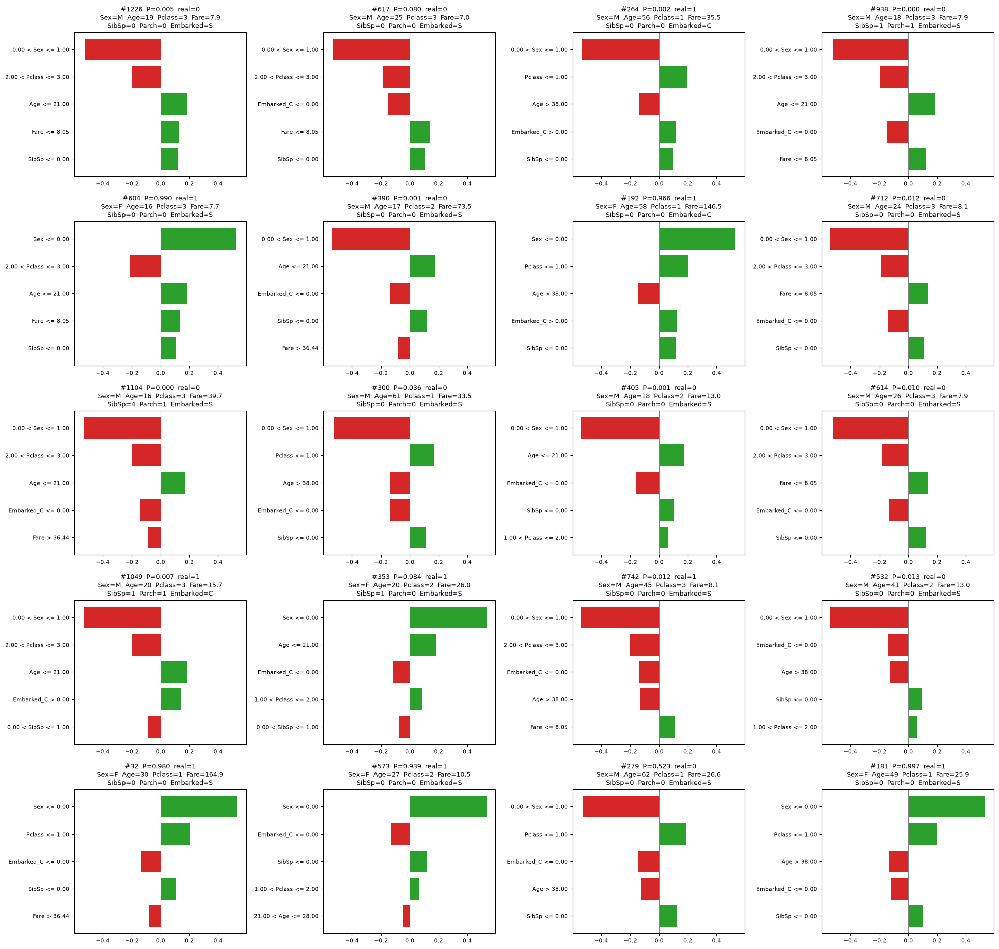

,Passenger,Real,P(Survived),Top 3 conditions (weights),Intercept,Local prediction,R2
5,1226,0,0.005,0.00 < Sex <= 1.00 (-0.523); 2.00 < Pclass <= 3.00 (-0.201); Age <= 21.00 (+0.185),0.652,0.365,0.509
6,617,0,0.080,0.00 < Sex <= 1.00 (-0.533); 2.00 < Pclass <= 3.00 (-0.188); Embarked_C <= 0.00 (-0.149),0.831,0.208,0.504
7,264,1,0.002,0.00 < Sex <= 1.00 (-0.537); Pclass <= 1.00 (+0.195); Age > 38.00 (-0.138),0.614,0.354,0.484
8,938,0,0.000,0.00 < Sex <= 1.00 (-0.522); 2.00 < Pclass <= 3.00 (-0.199); Age <= 21.00 (+0.188),0.861,0.299,0.501
9,604,1,0.990,Sex <= 0.00 (+0.527); 2.00 < Pclass <= 3.00 (-0.214); Age <= 21.00 (+0.187),0.143,0.886,0.520
10,390,0,0.001,0.00 < Sex <= 1.00 (-0.539); Age <= 21.00 (+0.172); Embarked_C <= 0.00 (-0.141),0.740,0.276,0.456
11,192,1,0.966,Sex <= 0.00 (+0.531); Pclass <= 1.00 (+0.199); Age > 38.00 (-0.147),0.072,0.894,0.488
12,712,0,0.012,0.00 < Sex <= 1.00 (-0.541); 2.00 < Pclass <= 3.00 (-0.192); Fare <= 8.05 (+0.140),0.829,0.204,0.512
13,1104,0,0.000,0.00 < Sex <= 1.00 (-0.531); 2.00 < Pclass <= 3.00 (-0.200); Age <= 21.00 (+0.173),0.915,0.124,0.499
14,300,0,0.036,0.00 < Sex <= 1.00 (-0.528); Pclass <= 1.00 (+0.170); Age > 38.00 (-0.138),0.743,0.223,0.476


In [50]:
exps_25, rows_25 = zip(*[explain_passenger(i) for i in range(25)])
table_25 = pd.DataFrame(rows_25)

table_5  = table_25.iloc[:5]     # passageiros 0–4
table_20 = table_25.iloc[5:25]   # passageiros 5–24 → 20 passageiros
exps_20  = exps_25[5:25]

pd.set_option('display.max_colwidth', None)
display(table_5.head(5))
#show_many(exps_20, table_20)  
plot_grid(exps_20, table_20)
display(table_20)

Resumo dos 20 passageiros: quantas vezes cada feature aparece nas 5 principais, quantas vezes ajuda ou prejudica, e o peso médio.

In [51]:
weights_20 = pd.DataFrame(
    [{feature_names[f]: w for f, w in exp.as_map()[1]} for exp in exps_20],
    index=table_20['Passenger'])

summary = pd.DataFrame({
    'Aparece': weights_20.notna().sum(),
    'Ajuda (+)': (weights_20 > 0).sum(),
    'Prejudica (-)': (weights_20 < 0).sum(),
    'Peso médio': weights_20.mean().round(3),
}).sort_values('Aparece', ascending=False)
display(summary)

,Aparece,Ajuda (+),Prejudica (-),Peso médio
Sex,20,6,14,-0.212
Pclass,19,10,9,-0.019
Embarked_C,18,3,15,-0.094
SibSp,17,15,2,0.089
Age,16,8,8,0.029
Fare,10,7,3,0.067


Gráficos do resumo: frequência de cada feature e distribuição dos pesos.

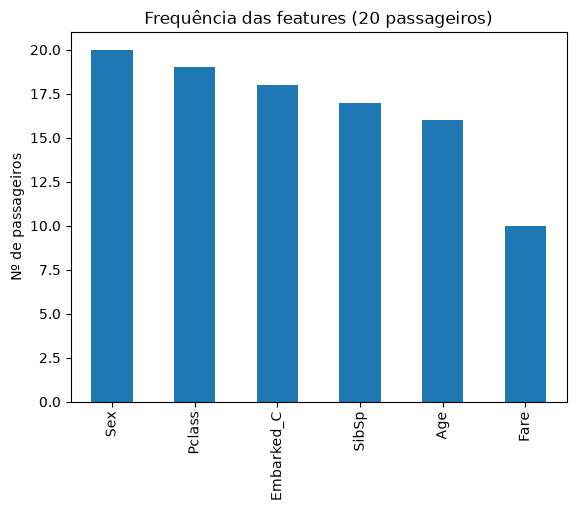

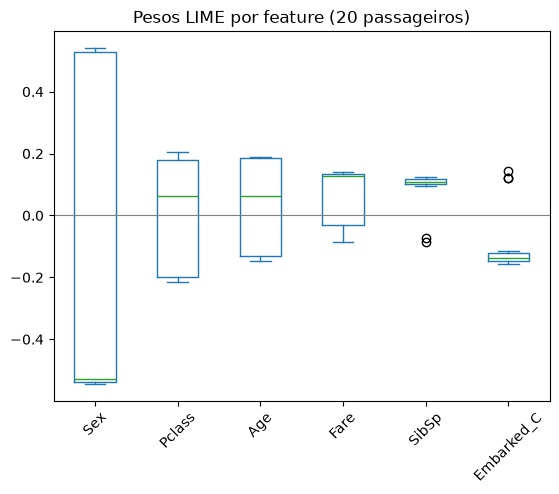

In [52]:
summary['Aparece'].plot.bar(title='Frequência das features (20 passageiros)')
plt.ylabel('Nº de passageiros'); plt.show()

weights_20.plot.box(rot=45, title='Pesos LIME por feature (20 passageiros)')
plt.axhline(0, color='grey', lw=0.8); plt.show()

Pesos por condição nos 25 passageiros: número de ocorrências, média, mínimo e máximo. Permite ver se a mesma condição pesa o mesmo em passageiros diferentes.

In [53]:
cond_weights = pd.DataFrame(
    [{'Passenger': pid, 'Condição': cond, 'Peso': w}
     for pid, exp in zip(table_25['Passenger'], exps_25)
     for cond, w in exp.as_list()])

cond_summary = (cond_weights.groupby('Condição')['Peso']
                .agg(['count', 'mean', 'min', 'max'])
                .round(3)
                .sort_values('count', ascending=False))
display(cond_summary)

,count,mean,min,max
Condição,,,,
Embarked_C <= 0.00,20,-0.140,-0.173,-0.114
0.00 < Sex <= 1.00,18,-0.531,-0.545,-0.519
SibSp <= 0.00,18,0.112,0.095,0.124
2.00 < Pclass <= 3.00,12,-0.199,-0.214,-0.182
Age <= 21.00,10,0.179,0.161,0.188
Age > 38.00,8,-0.136,-0.147,-0.128
Sex <= 0.00,7,0.533,0.527,0.541
Fare <= 8.05,7,0.130,0.110,0.140
Pclass <= 1.00,7,0.191,0.170,0.205


Exemplo do passageiro #935: a previsão local é o intercept mais a soma dos pesos. Como o modelo é linear, o resultado pode sair do intervalo [0, 1].

In [54]:
pos_935 = table_25.index[table_25['Passenger'] == 935][0]
exp_935 = exps_25[pos_935]

soma_935 = exp_935.intercept[1] + sum(w for _, w in exp_935.as_list())

print(f'Intercept: {exp_935.intercept[1]:.3f}')
for cond, w in exp_935.as_list():
    print(f'{cond}: {w:+.3f}')
print(f'Intercept + pesos: {soma_935:.3f}')
print(f'Previsão local do LIME: {exp_935.local_pred[0]:.3f}')

Intercept: 0.863
0.00 < Sex <= 1.00: -0.527
2.00 < Pclass <= 3.00: -0.210
Embarked_C <= 0.00: -0.137
SibSp > 1.00: -0.124
Embarked_Q <= 0.00: +0.087
Intercept + pesos: -0.048
Previsão local do LIME: -0.048


# 2 · Fidelidade
Avalia até que ponto o modelo local reproduz o modelo original. Começa por explicar todos os passageiros do teste.

In [55]:
t0 = time.time()
exps_all, rows_all = zip(*[explain_passenger(i) for i in range(len(x_test))])
table_all = pd.DataFrame(rows_all)
print(f'{len(table_all)} passageiros em {time.time() - t0:.0f}s')

209 passageiros em 22s


Calcula o erro local |P − previsão local|, compara R² e erro por nível de confiança do modelo, e mostra os 5 piores casos de cada métrica.

In [56]:
fid = table_all[['Passenger', 'Real', 'P(Survived)', 'Local prediction', 'R2']].copy()
fid['|P - local_pred|'] = (fid['P(Survived)'] - fid['Local prediction']).abs().round(3)
fid['Confiança'] = pd.cut((fid['P(Survived)'] - 0.5).abs(), bins=[0, 0.2, 0.4, 0.5],
                          labels=['indeciso (0.3–0.7)', 'médio', 'confiante (<0.1 ou >0.9)'],
                          include_lowest=True)

display(fid.groupby('Confiança')[['R2', '|P - local_pred|']].agg(['mean', 'count']).round(3))
display(fid.sort_values('R2').head())                      # 5 com pior R²
display(fid.sort_values('|P - local_pred|', ascending=False).head())  # 5 com pior erro local

R2       |P - local_pred|      
                           mean count             mean count
Confiança                                                   
indeciso (0.3–0.7)        0.470    16            0.230    16
médio                     0.478    27            0.257    27
confiante (<0.1 ou >0.9)  0.477   166            0.212   166

,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
107,585,0,0.000,0.112,0.399,0.112,confiante (<0.1 ou >0.9)
95,346,0,0.004,0.241,0.419,0.237,confiante (<0.1 ou >0.9)
174,456,0,0.548,0.597,0.419,0.049,indeciso (0.3–0.7)
152,360,1,0.001,0.125,0.419,0.124,confiante (<0.1 ou >0.9)
181,375,0,0.006,0.209,0.419,0.203,confiante (<0.1 ou >0.9)


,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
206,674,1,0.914,0.038,0.490,0.876,confiante (<0.1 ou >0.9)
100,1257,1,0.052,0.768,0.499,0.716,confiante (<0.1 ou >0.9)
33,696,0,0.047,0.763,0.521,0.716,confiante (<0.1 ou >0.9)
177,378,0,0.829,0.122,0.435,0.707,médio
38,611,1,0.950,0.261,0.487,0.689,confiante (<0.1 ou >0.9)


R² e erro local em função da probabilidade prevista pelo modelo.

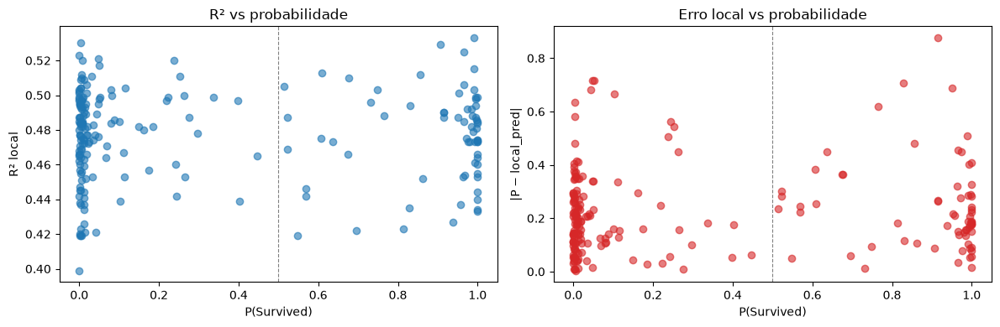

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fid['P(Survived)'], fid['R2'], alpha=0.6)
axes[0].set(xlabel='P(Survived)', ylabel='R² local', title='R² vs probabilidade')
axes[1].scatter(fid['P(Survived)'], fid['|P - local_pred|'], alpha=0.6, color='tab:red')
axes[1].set(xlabel='P(Survived)', ylabel='|P − local_pred|', title='Erro local vs probabilidade')
for ax in axes:
    ax.axvline(0.5, color='grey', ls='--', lw=0.8)
plt.tight_layout(); plt.savefig('ponto2_fidelidade.png', dpi=150); plt.show()

Mostra o passageiro com maior erro local e a respetiva explicação.

In [58]:
i_worst = fid['|P - local_pred|'].idxmax()
display(fid.loc[[i_worst]])
print(passenger_values(fid.loc[i_worst, 'Passenger']))
show_lime(exps_all[i_worst])

,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
206,674,1,0.914,0.038,0.49,0.876,confiante (<0.1 ou >0.9)


Sex=M  Age=32  Pclass=3  Fare=56.5
SibSp=0  Parch=0  Embarked=S


# 3 · Estabilidade
Explica o mesmo passageiro com 10 seeds e 3 valores de `num_samples`, para ver quanto muda a explicação e quanto tempo demora.

In [59]:
i_p = 0
x = x_test.iloc[i_p].astype(float).values
print(passenger_values(x_test.index[i_p]))

records, times = [], {}
for n in [500, 1000, 5000]:
    t0 = time.time()
    for seed in range(10):
        exp = make_explainer(seed=seed).explain_instance(x, predict_fn, num_features=5, num_samples=n)
        for f, w in exp.as_map()[1]:
            records.append({'num_samples': n, 'seed': seed, 'feature': feature_names[f], 'weight': w})
    times[n] = (time.time() - t0) / 10   # tempo médio por explicação

stab = pd.DataFrame(records)

Sex=M  Age=36  Pclass=3  Fare=9.5
SibSp=0  Parch=0  Embarked=S


Por feature e `num_samples`: quantas vezes aparece, peso médio, mínimo, máximo, desvio padrão, amplitude e se muda de sinal.

In [60]:
stab_sum = stab.groupby(['num_samples', 'feature'])['weight'].agg(
    vezes='count', peso_medio='mean', minimo='min', maximo='max', std='std')
stab_sum['amplitude'] = stab_sum['maximo'] - stab_sum['minimo']
stab_sum['muda_sinal'] = (stab_sum['minimo'] < 0) & (stab_sum['maximo'] > 0)
display(stab_sum.round(3))

vezes  peso_medio  minimo  maximo    std  amplitude  \
num_samples feature                                                           
500         Embarked_C     10      -0.138  -0.232  -0.075  0.048      0.157   
            Embarked_Q      4       0.129   0.092   0.154  0.026      0.062   
            Embarked_S      2      -0.082  -0.098  -0.066  0.022      0.032   
            Fare            3      -0.023  -0.072   0.066  0.077      0.138   
            Parch           1      -0.028  -0.028  -0.028    NaN      0.000   
            Pclass         10      -0.204  -0.275  -0.164  0.029      0.111   
            Sex            10      -0.524  -0.591  -0.474  0.036      0.117   
            SibSp          10       0.104   0.079   0.151  0.026      0.071   
1000        Age             2      -0.062  -0.064  -0.060  0.003      0.004   
            Embarked_C     10      -0.142  -0.174  -0.102  0.021      0.072   
            Embarked_Q      3       0.107   0.099   0.121  0.012      0.022   
            Parch           5      -0.061  -0.079  -0.038  0.017      0.041   
            Pclass         10      -0.197  -0.244  -0.155  0.024      0.089   
            Sex            10      -0.526  -0.557  -0.489  0.019      0.068   
            SibSp          10       0.106   0.073   0.124  0.017      0.050   
5000        Embarked_C     10      -0.144  -0.159  -0.129  0.010      0.030   
            Embarked_Q      8       0.080   0.073   0.089  0.006      0.017   
            Parch           2      -0.052  -0.069  -0.034  0.024      0.034   
            Pclass         10      -0.197  -0.210  -0.184  0.008      0.026   
            Sex            10      -0.532  -0.542  -0.518  0.009      0.024   
            SibSp          10       0.111   0.098   0.127  0.009      0.030   

                        muda_sinal  
num_samples feature                 
500         Embarked_C       False  
            Embarked_Q       False  
            Embarked_S       False  
            Fare              True  
            Parch            False  
            Pclass           False  
            Sex              False  
            SibSp            False  
1000        Age              False  
            Embarked_C       False  
            Embarked_Q       False  
            Parch            False  
            Pclass           False  
            Sex              False  
            SibSp            False  
5000        Embarked_C       False  
            Embarked_Q       False  
            Parch            False  
            Pclass           False  
            Sex              False  
            SibSp            False

Tabela resumo para o relatório, com uma linha por valor de `num_samples`.

In [61]:
compact = pd.DataFrame({
    n: {
        'Features (vezes)': ', '.join(f'{f}({v})' for f, v in g['vezes'].sort_values(ascending=False).items()),
        'Peso médio |w|': g['peso_medio'].abs().mean().round(3),
        'Amplitude média': g['amplitude'].mean().round(3),
        'Tempo/explicação (s)': round(times[n], 3),
    }
    for n, g in stab_sum.reset_index(level=0, drop=True).groupby(stab_sum.index.get_level_values(0))
}).T
display(compact)

,Features (vezes),Peso médio |w|,Amplitude média,Tempo/explicação (s)
500,"Embarked_C(10), SibSp(10), Sex(10), Pclass(10), Embarked_Q(4), Fare(3), Embarked_S(2), Parch(1)",0.154,0.086,0.083
1000,"Embarked_C(10), Sex(10), Pclass(10), SibSp(10), Parch(5), Embarked_Q(3), Age(2)",0.172,0.05,0.087
5000,"Embarked_C(10), Pclass(10), SibSp(10), Sex(10), Embarked_Q(8), Parch(2)",0.186,0.027,0.109


Distribuição dos pesos entre seeds para cada valor de `num_samples`.

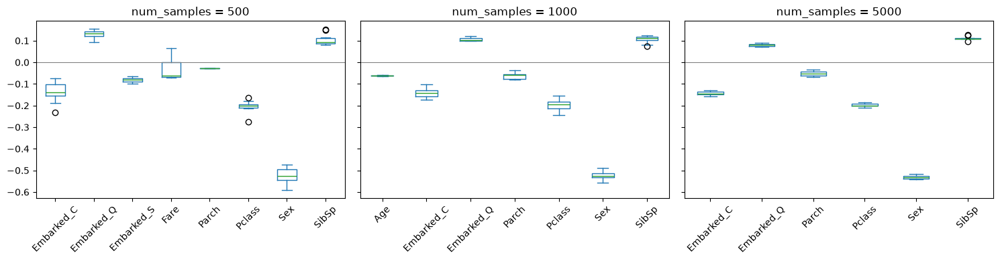

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes, [500, 1000, 5000]):
    d = stab[stab['num_samples'] == n].pivot(index='seed', columns='feature', values='weight')
    d.plot.box(ax=ax, rot=45, title=f'num_samples = {n}')
    ax.axhline(0, color='grey', lw=0.8)
plt.tight_layout(); plt.savefig('ponto3_estabilidade.png', dpi=150); plt.show()

# 4 · Mudar a representação
Explica o mesmo passageiro com `discretize_continuous=True` (intervalos) e `False` (variáveis contínuas).

In [63]:
x = x_test.iloc[0].astype(float).values

expl_disc = make_explainer(discretize=True)
expl_cont = make_explainer(discretize=False)
nf = len(feature_names)

exp_disc = expl_disc.explain_instance(x, predict_fn, num_features=nf)
exp_cont = expl_cont.explain_instance(x, predict_fn, num_features=nf)

show_lime(exp_disc)
show_lime(exp_cont)

Compara as duas versões. Com `False`, o peso é um coeficiente por desvio padrão e o efeito real é coef × z, por isso o sinal da barra pode não coincidir com o sinal do efeito.

In [64]:
z = (x - expl_cont.scaler.mean_) / expl_cont.scaler.scale_
disc = {feature_names[f]: (cond, w) for (cond, w), (f, _) in zip(exp_disc.as_list(), exp_disc.as_map()[1])}

comp = pd.DataFrame([{
    'Feature': feature_names[f],
    'Valor': x[f],
    'Condição (True)': disc[feature_names[f]][0],
    'Peso (True)': disc[feature_names[f]][1],
    'Coef. (False)': w,
    'z': z[f],
    'Efeito = coef × z': w * z[f],
} for f, w in exp_cont.as_map()[1]]).round(3)
comp['Sinal da barra = sinal do efeito?'] = np.sign(comp['Coef. (False)']) == np.sign(comp['Efeito = coef × z'])
display(comp)

print('True : local_pred =', round(exp_disc.local_pred[0], 3), ' R² =', round(exp_disc.score, 3))
print('False: local_pred =', round(exp_cont.local_pred[0], 3), ' R² =', round(exp_cont.score, 3))

,Feature,Valor,Condição (True),Peso (True),Coef. (False),z,Efeito = coef × z,Sinal da barra = sinal do efeito?
0,Sex,1.0,0.00 < Sex <= 1.00,-0.520,-0.222,0.785,-0.174,True
1,Pclass,3.0,2.00 < Pclass <= 3.00,-0.196,-0.124,0.947,-0.117,True
2,SibSp,0.0,SibSp <= 0.00,0.110,-0.037,-0.543,0.020,False
3,Age,36.0,28.00 < Age <= 38.00,-0.010,-0.035,0.441,-0.015,True
4,Fare,9.5,8.05 < Fare <= 15.75,-0.010,-0.028,-0.480,0.014,False
5,Embarked_Q,0.0,Embarked_Q <= 0.00,0.063,-0.003,-0.239,0.001,False
6,Embarked_C,0.0,Embarked_C <= 0.00,-0.148,-0.003,-0.515,0.002,False
7,Parch,0.0,Parch <= 0.00,-0.034,0.003,-0.501,-0.001,False
8,Embarked_S,1.0,0.00 < Embarked_S <= 1.00,-0.024,0.001,0.599,0.001,True


True : local_pred = 0.078  R² = 0.471
False: local_pred = 0.489  R² = 0.366


Intervalos vs variáveis categóricas: repete as explicações dos 25 passageiros indicando Sex, Pclass e Embarked como categóricas, e compara com a versão original.

,Passenger,P(Survived),Top 3 (intervalos),Top 3 (categóricas),R2 (intervalos),R2 (categóricas),Local (intervalos),Local (categóricas)
0,1298,0.003,0.00 < Sex <= 1.00 (-0.521); 2.00 < Pclass <= 3.00 (-0.196); Embarked_C <= 0.00 (-0.149),Sex=male (-0.516); Pclass=3 (-0.211); Embarked_C=0 (-0.143),0.469,0.465,0.096,0.089
1,321,0.523,0.00 < Sex <= 1.00 (-0.540); Pclass <= 1.00 (+0.182); Age > 38.00 (-0.142),Sex=male (-0.527); Pclass=1 (+0.199); Embarked_C=0 (-0.145),0.475,0.488,0.235,0.246
2,590,0.999,Sex <= 0.00 (+0.529); Age <= 21.00 (+0.161); Embarked_C <= 0.00 (-0.132),Sex=female (+0.529); Age <= 21.00 (+0.166); Embarked_C=0 (-0.139),0.457,0.450,0.805,0.806
3,935,0.000,0.00 < Sex <= 1.00 (-0.527); 2.00 < Pclass <= 3.00 (-0.210); Embarked_C <= 0.00 (-0.137),Sex=male (-0.538); Pclass=3 (-0.196); Embarked_C=0 (-0.130),0.462,0.463,-0.048,-0.063
4,704,0.051,0.00 < Sex <= 1.00 (-0.519); 2.00 < Pclass <= 3.00 (-0.202); Age <= 21.00 (+0.181),Sex=male (-0.518); Pclass=3 (-0.185); Age <= 21.00 (+0.181),0.502,0.503,0.237,0.381


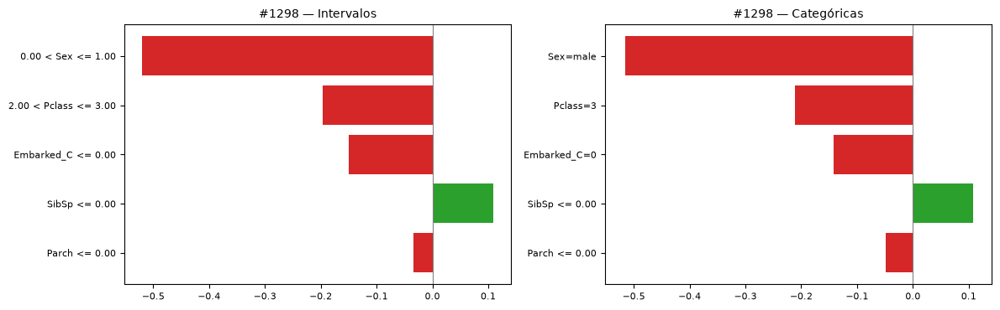

In [65]:
categorical = ['Sex', 'Pclass', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

explainer_cat = make_explainer(
    categorical_features=[feature_names.index(c) for c in categorical],
    categorical_names={feature_names.index('Sex'): ['female', 'male']})

exps_cat, rows_cat = zip(*[explain_passenger(i, explainer=explainer_cat) for i in range(25)])
table_cat = pd.DataFrame(rows_cat)

compare_cat = pd.DataFrame({
    'Passenger': table_25['Passenger'],
    'P(Survived)': table_25['P(Survived)'],
    'Top 3 (intervalos)': table_25['Top 3 conditions (weights)'],
    'Top 3 (categóricas)': table_cat['Top 3 conditions (weights)'],
    'R2 (intervalos)': table_25['R2'],
    'R2 (categóricas)': table_cat['R2'],
    'Local (intervalos)': table_25['Local prediction'],
    'Local (categóricas)': table_cat['Local prediction'],
})
display(compare_cat.head(5))


def plot_compare_cat(i, fname='intervalos_vs_categoricas.png'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
    for ax, exp, title in zip(axes, [exps_25[i], exps_cat[i]], ['Intervalos', 'Categóricas']):
        conds, weights = zip(*exp.as_list(label=1)[::-1])
        ax.barh(conds, weights, color=['tab:green' if w > 0 else 'tab:red' for w in weights])
        ax.axvline(0, color='grey', lw=0.8)
        ax.set_title(f"#{table_25['Passenger'].iloc[i]} — {title}", fontsize=10)
        ax.tick_params(labelsize=8)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()


plot_compare_cat(0)

Analisa a diferença na previsão local do passageiro #704 e mede as diferenças de R² e de previsão local nos 25 passageiros.

In [66]:
pos_704 = table_25.index[table_25['Passenger'] == 704][0]

display(pd.DataFrame({
    'Intervalos': [f'{c} ({w:+.3f})' for c, w in exps_25[pos_704].as_list()],
    'Categóricas': [f'{c} ({w:+.3f})' for c, w in exps_cat[pos_704].as_list()],
}))
print(f'Intercept (intervalos): {exps_25[pos_704].intercept[1]:.3f}')
print(f'Intercept (categóricas): {exps_cat[pos_704].intercept[1]:.3f}')

diff_cat = pd.DataFrame({
    'Passenger': table_25['Passenger'],
    '|Dif. R2|': (table_25['R2'] - table_cat['R2']).abs(),
    '|Dif. previsão local|': (table_25['Local prediction'] - table_cat['Local prediction']).abs(),
})
display(diff_cat.drop(columns='Passenger').agg(['mean', 'max']).round(3))
display(diff_cat.sort_values('|Dif. previsão local|', ascending=False).head(5))

,Intervalos,Categóricas
0,0.00 < Sex <= 1.00 (-0.519),Sex=male (-0.518)
1,2.00 < Pclass <= 3.00 (-0.202),Pclass=3 (-0.185)
2,Age <= 21.00 (+0.181),Age <= 21.00 (+0.181)
3,Embarked_C <= 0.00 (-0.173),Fare <= 8.05 (+0.148)
4,SibSp <= 0.00 (+0.119),SibSp <= 0.00 (+0.124)


Intercept (intervalos): 0.831
Intercept (categóricas): 0.631


,|Dif. R2|,|Dif. previsão local|
mean,0.010,0.029
max,0.038,0.144


,Passenger,|Dif. R2|,|Dif. previsão local|
4,704,0.001,0.144
5,1226,0.001,0.117
9,604,0.010,0.094
10,390,0.023,0.059
22,573,0.009,0.054


# 5 · SP-LIME
`run_sp` escolhe um conjunto de explicações que cubra o máximo de features importantes e devolve os passageiros selecionados.

In [67]:
def run_sp(n_exps, seed=42, data=x_test):
    sp = submodular_pick.SubmodularPick(make_explainer(seed=seed), data.astype(float).values, predict_fn,
                                        method='full', num_features=5, num_exps_desired=n_exps)
    rows = []
    for k, (i, exp) in enumerate(zip(sp.V, sp.sp_explanations)):
        pid, label = data.index[i], exp.available_labels()[0]
        rows.append({
            'Ordem': k + 1,
            'Passenger': pid,
            'Real': y_test.loc[pid],
            'P(Survived)': round(predict_fn(data.loc[[pid]].astype(float).values)[0, 1], 3),
            'Classe explicada': ['Did not Survive', 'Survived'][label],
            'Valores': passenger_values(pid).replace('\n', '  '),
            'Condições (pesos)': '; '.join(f'{c} ({w:+.3f})' for c, w in exp.as_list(label=label)),
        })
    return sp, pd.DataFrame(rows)

Seleciona 3 e 5 explicações, e repete a de 5 com outra seed para ver se os passageiros mudam.

In [68]:
t0 = time.time()
sp3, sel3 = run_sp(3)
sp5, sel5 = run_sp(5)
sp5b, sel5b = run_sp(5, seed=10)
print(f'{time.time() - t0:.0f}s')

display(sel3); display(sel5); display(sel5b)
print('Mesmos passageiros com outra seed?', set(sel5['Passenger']) == set(sel5b['Passenger']))

65s


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1093,0,0.101,Did not Survive,Sex=M Age=16 Pclass=3 Fare=9.2 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.531); 2.00 < Pclass <= 3.00 (+0.187); Age <= 21.00 (-0.178); Embarked_C <= 0.00 (+0.144); SibSp <= 0.00 (-0.117)
1,2,282,1,0.999,Survived,Sex=F Age=52 Pclass=1 Fare=78.3 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.527); Pclass <= 1.00 (+0.202); Embarked_C > 0.00 (+0.140); Age > 38.00 (-0.138); 0.00 < SibSp <= 1.00 (-0.086)
2,3,838,0,0.000,Did not Survive,Sex=M Age=28 Pclass=3 Fare=7.9 SibSp=2 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.516); 2.00 < Pclass <= 3.00 (+0.200); Fare <= 8.05 (-0.134); SibSp > 1.00 (+0.134); Embarked_C <= 0.00 (+0.131)


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1093,0,0.101,Did not Survive,Sex=M Age=16 Pclass=3 Fare=9.2 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.531); 2.00 < Pclass <= 3.00 (+0.187); Age <= 21.00 (-0.178); Embarked_C <= 0.00 (+0.144); SibSp <= 0.00 (-0.117)
1,2,282,1,0.999,Survived,Sex=F Age=52 Pclass=1 Fare=78.3 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.527); Pclass <= 1.00 (+0.202); Embarked_C > 0.00 (+0.140); Age > 38.00 (-0.138); 0.00 < SibSp <= 1.00 (-0.086)
2,3,838,0,0.000,Did not Survive,Sex=M Age=28 Pclass=3 Fare=7.9 SibSp=2 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.516); 2.00 < Pclass <= 3.00 (+0.200); Fare <= 8.05 (-0.134); SibSp > 1.00 (+0.134); Embarked_C <= 0.00 (+0.131)
3,4,340,1,0.999,Survived,Sex=F Age=4 Pclass=2 Fare=39.0 SibSp=2 Parch=1 Embarked=S,Sex <= 0.00 (+0.528); Age <= 21.00 (+0.175); Embarked_C <= 0.00 (-0.126); Fare > 36.44 (-0.080); 1.00 < Pclass <= 2.00 (+0.076)
4,5,508,0,0.002,Did not Survive,Sex=M Age=54 Pclass=2 Fare=14.0 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.529); Age > 38.00 (+0.145); Embarked_C <= 0.00 (+0.139); SibSp <= 0.00 (-0.103); Embarked_Q <= 0.00 (-0.094)


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1093,0,0.101,Did not Survive,Sex=M Age=16 Pclass=3 Fare=9.2 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.527); 2.00 < Pclass <= 3.00 (+0.200); Age <= 21.00 (-0.185); Embarked_C <= 0.00 (+0.143); SibSp <= 0.00 (-0.111)
1,2,282,1,0.999,Survived,Sex=F Age=52 Pclass=1 Fare=78.3 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.530); Pclass <= 1.00 (+0.202); Embarked_C > 0.00 (+0.148); Age > 38.00 (-0.135); Fare > 36.44 (-0.077)
2,3,378,0,0.829,Survived,Sex=M Age=31 Pclass=2 Fare=26.2 SibSp=1 Parch=1 Embarked=S,0.00 < Sex <= 1.00 (-0.531); Embarked_C <= 0.00 (-0.115); 1.00 < Pclass <= 2.00 (+0.087); 0.00 < SibSp <= 1.00 (-0.083); 15.75 < Fare <= 36.44 (-0.077)
3,4,838,0,0.000,Did not Survive,Sex=M Age=28 Pclass=3 Fare=7.9 SibSp=2 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.520); 2.00 < Pclass <= 3.00 (+0.198); Embarked_C <= 0.00 (+0.140); SibSp > 1.00 (+0.132); Fare <= 8.05 (-0.120)
4,5,348,0,0.005,Did not Survive,Sex=M Age=27 Pclass=2 Fare=13.0 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.548); Embarked_C <= 0.00 (+0.134); SibSp <= 0.00 (-0.116); 1.00 < Pclass <= 2.00 (-0.075); 21.00 < Age <= 28.00 (+0.045)


Mesmos passageiros com outra seed? False


Cobertura: importância global de cada feature e se aparece nas explicações selecionadas.

In [69]:
def coverage(sp):
    imp = {}
    for exp in sp.explanations:                      # todos os candidatos = visão "global"
        lab = exp.available_labels()[0]
        for f, w in exp.as_map()[lab]:
            imp[feature_names[f]] = imp.get(feature_names[f], 0) + abs(w)
    covered = {feature_names[f] for exp in sp.sp_explanations
               for f, _ in exp.as_map()[exp.available_labels()[0]]}
    t = pd.Series(imp).sort_values(ascending=False).round(2).to_frame('Importância global Σ|w|')
    t['Coberta pelo SP?'] = t.index.isin(covered)
    return t

display(coverage(sp5))

,Importância global Σ|w|,Coberta pelo SP?
Sex,110.90,True
Pclass,34.46,True
Embarked_C,27.45,True
Age,19.60,True
SibSp,19.55,True
Fare,9.98,True
Embarked_Q,0.86,True
Parch,0.40,False


Representatividade: compara as médias dos passageiros selecionados com as do teste e mostra as 5 explicações.

In [70]:
sel = sel5['Passenger']
rep = pd.DataFrame({
    'Teste (média)': x_test.astype(float).mean(),
    'SP-LIME (média)': x_test.loc[sel].astype(float).mean(),
}).round(2)
rep.loc['Survived (real)'] = [y_test.mean().round(2), y_test.loc[sel].mean().round(2)]
display(rep)

for exp, (_, row) in zip(sp5.sp_explanations, sel5.iterrows()):
    display(HTML(f"<h4>Passageiro {row['Passenger']} — real: {row['Real']} | "
                 f"P(Survived) = {row['P(Survived)']} | classe explicada: {row['Classe explicada']}</h4>"))
    show_lime(exp)

,Teste (média),SP-LIME (média)
Pclass,2.23,2.20
Sex,0.67,0.60
Age,30.07,30.80
SibSp,0.50,1.00
Parch,0.42,0.20
Fare,34.91,29.68
Embarked_C,0.18,0.20
Embarked_Q,0.02,0.00
Embarked_S,0.80,0.80
Survived (real),0.40,0.40


# 6 · Extra
Largura do kernel usada por omissão pelo LIME: 0.75 × raiz do número de features.

In [71]:
default_kernel_width = 0.75 * np.sqrt(x_train.shape[1])
print(f'Largura do kernel por omissão: {default_kernel_width:.3f}')

Largura do kernel por omissão: 2.250


Efeito da largura do kernel no R² e no erro local, em 50 passageiros. A linha tracejada marca o valor por omissão.

,R2,erro_local
kernel_width,,
0.5,0.342,0.203
1.0,0.467,0.219
2.0,0.482,0.218
3.0,0.484,0.215
5.0,0.485,0.215


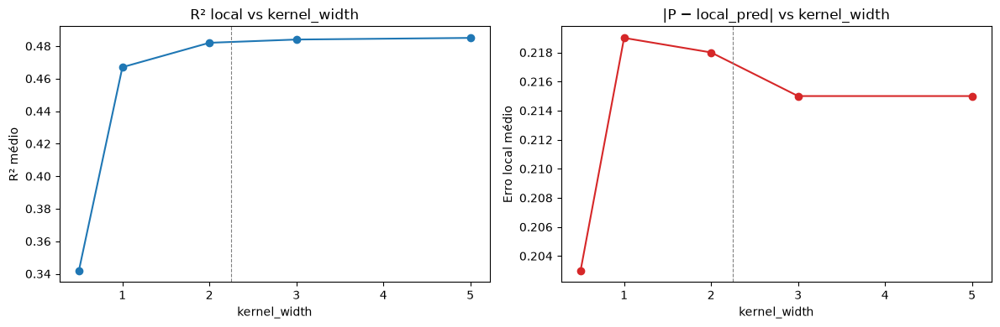

In [72]:
res = []
for kw in [0.5, 1, 2, 3, 5]:
    expl = make_explainer(kernel_width=kw)
    for i in range(50):
        x_i = x_test.iloc[i].astype(float).values
        e = expl.explain_instance(x_i, predict_fn, num_features=5)
        p = predict_fn(x_i.reshape(1, -1))[0, 1]
        res.append({'kernel_width': kw, 'R2': e.score, 'erro_local': abs(p - e.local_pred[0])})

kw_res = pd.DataFrame(res).groupby('kernel_width').mean().round(3)
display(kw_res)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
kw_res['R2'].plot(ax=axes[0], marker='o', title='R² local vs kernel_width')
axes[0].set_ylabel('R² médio')
kw_res['erro_local'].plot(ax=axes[1], marker='o', color='tab:red', title='|P − local_pred| vs kernel_width')
axes[1].set_ylabel('Erro local médio')
for ax in axes:
    ax.axvline(np.sqrt(len(feature_names)) * 0.75, color='grey', ls='--', lw=0.8)  # valor default
plt.tight_layout(); plt.savefig('ponto6_kernel_width.png', dpi=150); plt.show()

Compara a importância global do LIME (soma dos pesos absolutos, normalizada) com a importância interna do XGBoost (gain).

,LIME Σ|w|,XGBoost (gain)
Sex,0.495,0.495
Pclass,0.154,0.189
Embarked_C,0.124,0.043
SibSp,0.088,0.102
Age,0.088,0.033
Fare,0.045,0.034
Embarked_Q,0.005,0.033
Parch,0.001,0.038
Embarked_S,0.000,0.031


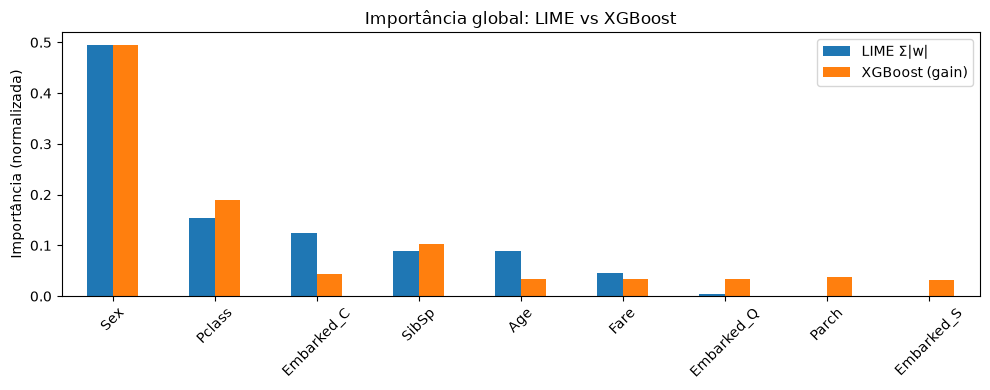

In [73]:
lime_imp = pd.Series(0.0, index=feature_names)
for e in exps_all:
    for f, w in e.as_map()[1]:
        lime_imp[feature_names[f]] += abs(w)

imp = pd.DataFrame({
    'LIME Σ|w|': lime_imp / lime_imp.sum(),
    'XGBoost (gain)': pd.Series(model.feature_importances_, index=feature_names),
}).round(3).sort_values('LIME Σ|w|', ascending=False)
display(imp)

imp.plot.bar(figsize=(10, 4), rot=45, title='Importância global: LIME vs XGBoost')
plt.ylabel('Importância (normalizada)')
plt.tight_layout(); plt.savefig('ponto6_importancia.png', dpi=150); plt.show()